# Walmart Retail Sales Forecasting

# Objective
Analyze historical Walmart sales data and identify trends and seasonal pattern.

# Tools
Python, Pandas, NumPy, Matplotlib, Seaborn

# Workflow
1. Data Loading
2. Data Cleaning
3. Exploratory Data Analysis (EDA)
4. Feature Engineering
5. Statistical Forecasting
6. Visualization and Business Insights

# Outcome
identify sales trends, seasonal pattern, and estimate future weekly sales using statistical

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


C:\Users\Dell Latitude\AppData\Local\Temp\ipykernel_10508\3842127725.py:5: UserWarning: This is a warning!
  warnings.warn('This is a warning!')


Pandas

In [3]:
pd.set_option('display.float_format', lambda x: '%.2f' % x)

In [4]:
train = pd.read_csv('train.csv/train.csv')
features = pd.read_csv('features.csv/features.csv')
stores = pd.read_csv('stores.csv')
test = pd.read_csv('test.csv/test.csv')

In [5]:
train.head(10)

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False
5,1,1,2010-03-12,21043.39,False
6,1,1,2010-03-19,22136.64,False
7,1,1,2010-03-26,26229.21,False
8,1,1,2010-04-02,57258.43,False
9,1,1,2010-04-09,42960.91,False


In [6]:
train.shape

(421570, 5)

In [7]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Store         421570 non-null  int64  
 1   Dept          421570 non-null  int64  
 2   Date          421570 non-null  str    
 3   Weekly_Sales  421570 non-null  float64
 4   IsHoliday     421570 non-null  bool   
dtypes: bool(1), float64(1), int64(2), str(1)
memory usage: 13.3 MB


In [8]:
train.isnull().sum()

Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
dtype: int64

In [9]:
train.duplicated().sum()

np.int64(0)

In [10]:
train['Date'].dtype             # converting str to datetime

<StringDtype(storage='python', na_value=nan)>

In [77]:
train['Date'] = pd.to_datetime(train['Date'])

In [12]:
train['Date'].dtype

dtype('<M8[us]')

In [13]:
train['Weekly_Sales'].dtype

dtype('float64')

In [14]:
train['IsHoliday'].dtype

dtype('bool')

Matplotlib

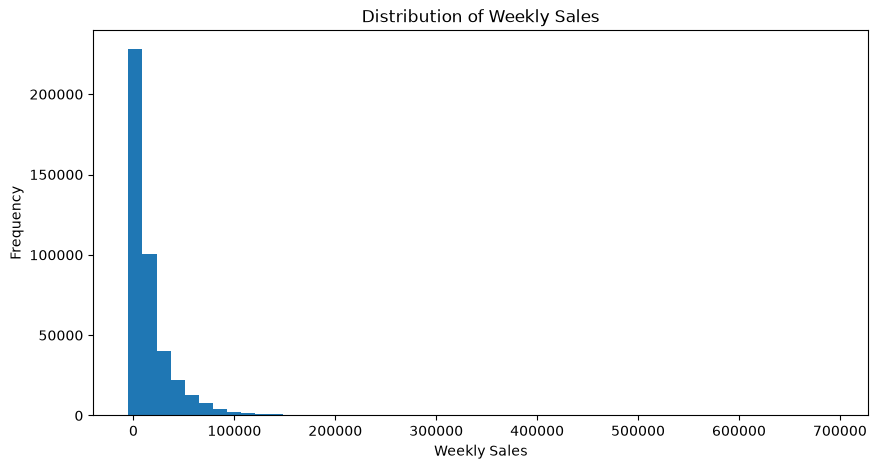

In [87]:
plt.figure(figsize=(10,5))

plt.hist(train['Weekly_Sales'],bins=50)

plt.title('Distribution of Weekly Sales')
plt.xlabel('Weekly Sales')
plt.ylabel('Frequency')

plt.show()

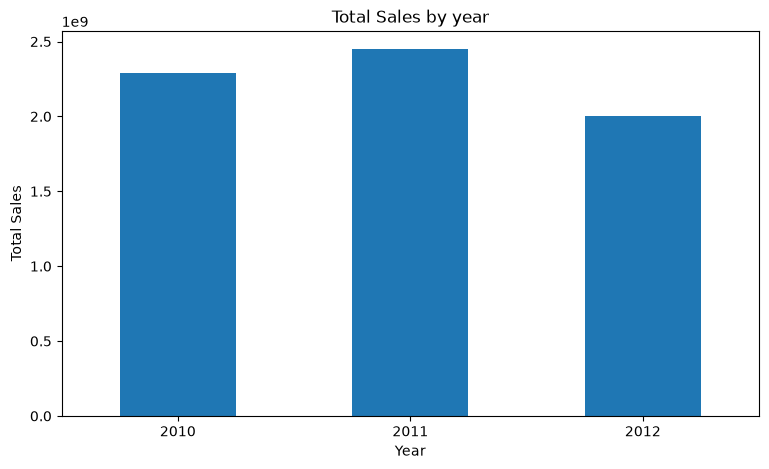

In [95]:
yearly_sales = train.groupby('Year')['Weekly_Sales'].sum()

yearly_sales

yearly_sales.plot(kind='bar', figsize=(9,5))

plt.title('Total Sales by year')
plt.xlabel('Year')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.show()

In [ ]:
train['Month'] = train['Date'].dt.month
train[['Date','Month']].head()

,Date,Month
0,2010-02-05,2
1,2010-02-12,2
2,2010-02-19,2
3,2010-02-26,2
4,2010-03-05,3


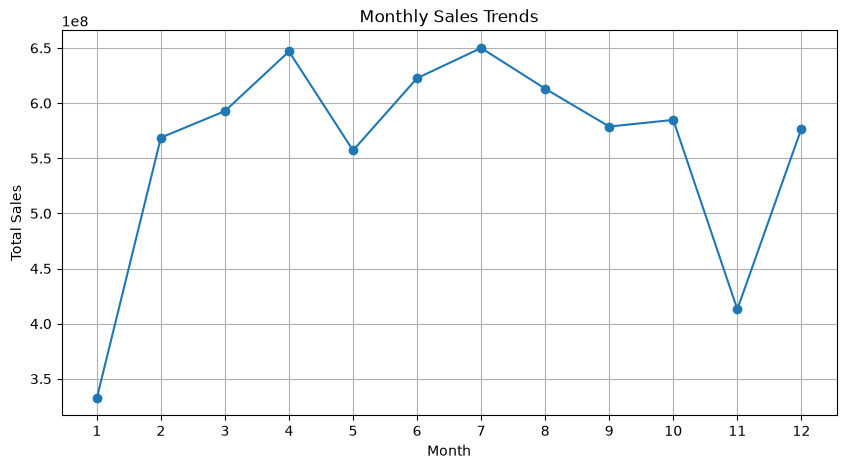

In [ ]:
monthly_sales = train.groupby('Month')['Weekly_Sales'].sum()

monthly_sales.plot(kind='line', marker= 'o', figsize=(10,5))

plt.title('Monthly Sales Trends')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(range(1,13))
plt.grid()
plt.show()           # combine monthly sales of 2010,2011,2012                                 

In [ ]:
train['Year'] = train['Date'].dt.year

train[['Date','Year','Month']].head()

,Date,Year,Month
0,2010-02-05,2010,2
1,2010-02-12,2010,2
2,2010-02-19,2010,2
3,2010-02-26,2010,2
4,2010-03-05,2010,3


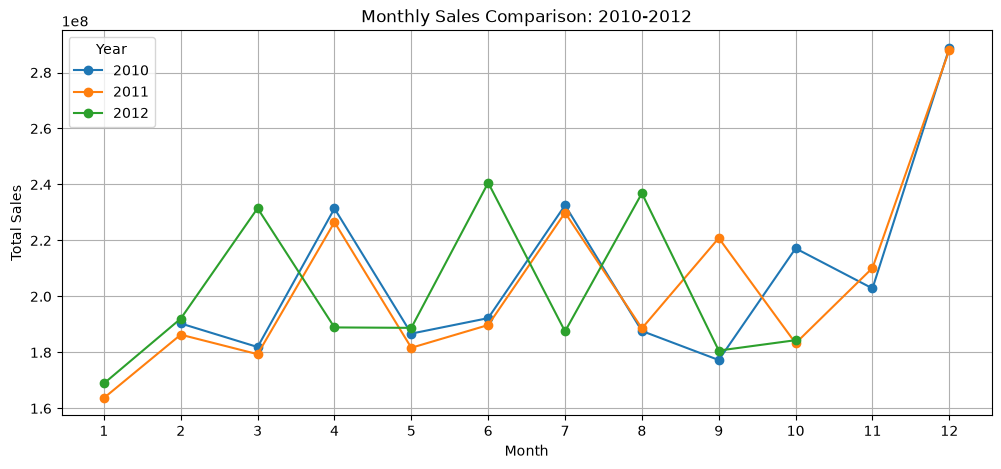

In [ ]:
year_month_sales = train.groupby(['Year','Month'])['Weekly_Sales'].sum().unstack()

year_month_sales.T.plot(figsize=(12,5), marker='o')        # T means Transpose

plt.title('Monthly Sales Comparison: 2010-2012')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(range(1,13))
plt.legend(title='Year')
plt.grid()
plt.show()

In [ ]:
holiday_sales = train.groupby('IsHoliday')['Weekly_Sales'].sum()
print(holiday_sales)

IsHoliday
False   6231919435.55
True     505299551.56
Name: Weekly_Sales, dtype: float64


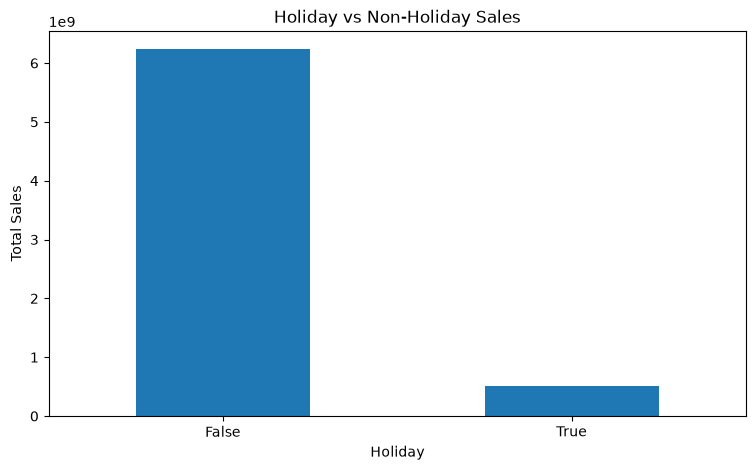

In [ ]:

holiday_sales.plot(kind='bar', figsize=(9,5))

plt.title('Holiday vs Non-Holiday Sales')
plt.xlabel('Holiday')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.show()

IsHoliday
False   15901.45
True    17035.82
Name: Weekly_Sales, dtype: float64


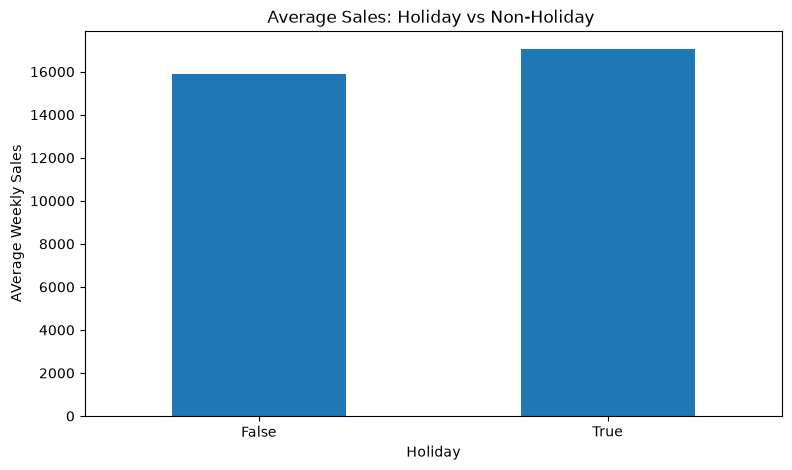

In [ ]:
holiday_avg = train.groupby('IsHoliday')['Weekly_Sales'].mean()
print(holiday_avg)
holiday_avg.plot(kind='bar', figsize=(9,5))

plt.title('Average Sales: Holiday vs Non-Holiday ')
plt.xlabel('Holiday')
plt.ylabel('AVerage Weekly Sales')
plt.xticks(rotation=0)
plt.show()

In [17]:
stores.head(10)

,Store,Type,Size
0,1,A,151315
1,2,A,202307
2,3,B,37392
3,4,A,205863
4,5,B,34875
5,6,A,202505
6,7,B,70713
7,8,A,155078
8,9,B,125833
9,10,B,126512


In [18]:
stores_sales = train.groupby('Store')['Weekly_Sales'].sum()

top_stores = stores_sales.sort_values(ascending=False).head(10)

print(top_stores)            # identify top 10 stores generating the highest total sales



Store
20   301397792.46
4    299543953.38
14   288999911.34
13   286517703.80
2    275382440.98
10   271617713.89
27   253855916.88
6    223756130.64
1    222402808.85
39   207445542.47
Name: Weekly_Sales, dtype: float64


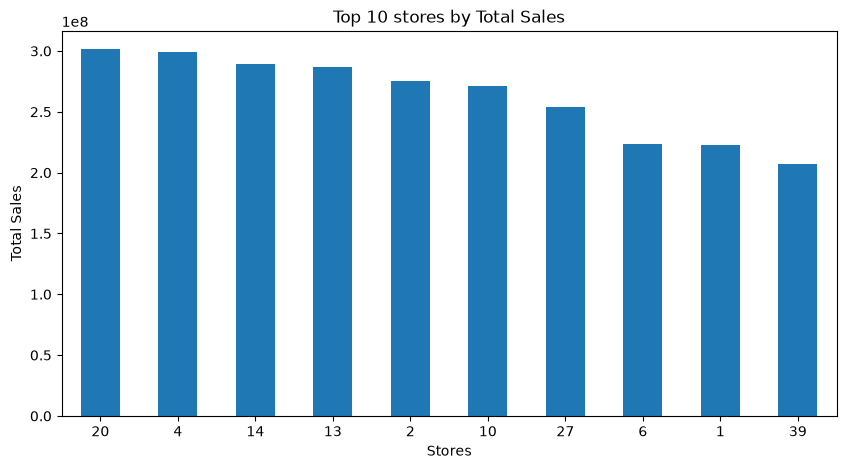

In [19]:
top_stores.plot(kind='bar', figsize=(10,5))

plt.title('Top 10 stores by Total Sales')
plt.xlabel('Stores')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)

plt.show()

In [20]:
dept_sales = train.groupby('Dept')['Weekly_Sales'].sum()

top_dept = dept_sales.sort_values(ascending=False).head(10)
print(top_dept)

Dept
92   483943341.87
95   449320162.52
38   393118136.92
72   305725152.21
90   291068463.68
40   288936022.05
2    280611174.43
91   216781705.73
13   197321569.95
8    194280780.73
Name: Weekly_Sales, dtype: float64


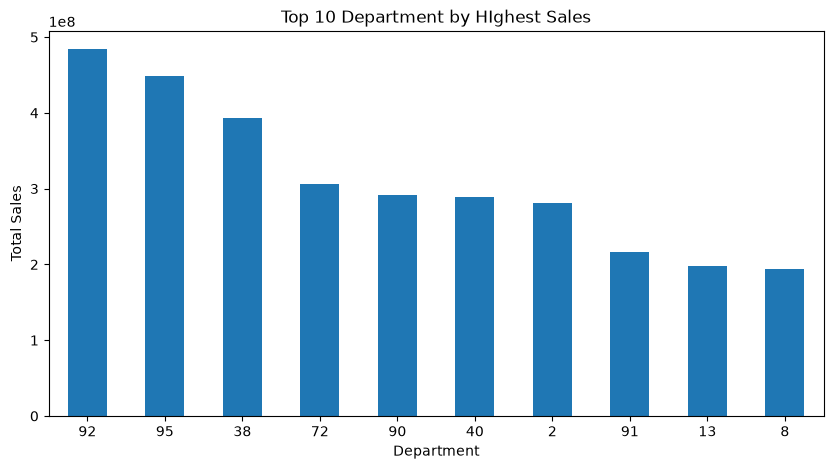

In [21]:
top_dept.plot(kind='bar', figsize=(10,5))

plt.title('Top 10 Department by HIghest Sales')
plt.xlabel('Department')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)

plt.show()

In [22]:
train = pd.read_csv('train.csv/train.csv')

In [23]:
train = train.merge(stores, on='Store', how='left')

train.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size
0,1,1,2010-02-05,24924.50,False,A,151315
1,1,1,2010-02-12,46039.49,True,A,151315
2,1,1,2010-02-19,41595.55,False,A,151315
3,1,1,2010-02-26,19403.54,False,A,151315
4,1,1,2010-03-05,21827.90,False,A,151315


In [24]:
train = train.merge(features, on=['Store', 'Date', 'IsHoliday'], how='left')

train.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment
0,1,1,2010-02-05,24924.50,False,A,151315,42.31,2.57,NaN,NaN,NaN,NaN,NaN,211.10,8.11
1,1,1,2010-02-12,46039.49,True,A,151315,38.51,2.55,NaN,NaN,NaN,NaN,NaN,211.24,8.11
2,1,1,2010-02-19,41595.55,False,A,151315,39.93,2.51,NaN,NaN,NaN,NaN,NaN,211.29,8.11
3,1,1,2010-02-26,19403.54,False,A,151315,46.63,2.56,NaN,NaN,NaN,NaN,NaN,211.32,8.11
4,1,1,2010-03-05,21827.90,False,A,151315,46.50,2.62,NaN,NaN,NaN,NaN,NaN,211.35,8.11


In [25]:
train.isnull().sum()

Store                0
Dept                 0
Date                 0
Weekly_Sales         0
IsHoliday            0
Type                 0
Size                 0
Temperature          0
Fuel_Price           0
MarkDown1       270889
MarkDown2       310322
MarkDown3       284479
MarkDown4       286603
MarkDown5       270138
CPI                  0
Unemployment         0
dtype: int64

In [26]:
train = train.loc[:,~train.columns.duplicated()] #removing duplicates

In [27]:
train.columns.to_list()

['Store',
 'Dept',
 'Date',
 'Weekly_Sales',
 'IsHoliday',
 'Type',
 'Size',
 'Temperature',
 'Fuel_Price',
 'MarkDown1',
 'MarkDown2',
 'MarkDown3',
 'MarkDown4',
 'MarkDown5',
 'CPI',
 'Unemployment']

In [28]:
train = pd.read_csv('train.csv/train.csv')
train['Date'] = pd.to_datetime(train['Date'])

In [29]:
train = train.merge(stores, on='Store', how='left')

In [30]:
features['Date'] = pd.to_datetime(features['Date'])

In [31]:
print(train['Date'].dtype)
print(features['Date'].dtype)

datetime64[us]
datetime64[us]


In [32]:
train = train.merge(features, on=['Store', 'Date', 'IsHoliday'], how='left')

In [33]:
train.shape

(421570, 16)

In [34]:
train.isnull().sum()

Store                0
Dept                 0
Date                 0
Weekly_Sales         0
IsHoliday            0
Type                 0
Size                 0
Temperature          0
Fuel_Price           0
MarkDown1       270889
MarkDown2       310322
MarkDown3       284479
MarkDown4       286603
MarkDown5       270138
CPI                  0
Unemployment         0
dtype: int64

In [35]:
(train.isnull().mean() * 100).round(2)

Store           0.00
Dept            0.00
Date            0.00
Weekly_Sales    0.00
IsHoliday       0.00
Type            0.00
Size            0.00
Temperature     0.00
Fuel_Price      0.00
MarkDown1      64.26
MarkDown2      73.61
MarkDown3      67.48
MarkDown4      67.98
MarkDown5      64.08
CPI             0.00
Unemployment    0.00
dtype: float64

EDA

In [36]:
train[['Date', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5']].head(10)   

,Date,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5
0,2010-02-05,NaN,NaN,NaN,NaN,NaN
1,2010-02-12,NaN,NaN,NaN,NaN,NaN
2,2010-02-19,NaN,NaN,NaN,NaN,NaN
3,2010-02-26,NaN,NaN,NaN,NaN,NaN
4,2010-03-05,NaN,NaN,NaN,NaN,NaN
5,2010-03-12,NaN,NaN,NaN,NaN,NaN
6,2010-03-19,NaN,NaN,NaN,NaN,NaN
7,2010-03-26,NaN,NaN,NaN,NaN,NaN
8,2010-04-02,NaN,NaN,NaN,NaN,NaN
9,2010-04-09,NaN,NaN,NaN,NaN,NaN


In [37]:
train.groupby(train['Date'].dt.year)[['MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 
'MarkDown5']].apply(lambda x : x.isnull().mean() * 100).round(2)

,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5
Date,,,,,
2010,100.00,100.00,100.00,100.00,100.00
2011,84.56,86.87,84.94,86.29,84.36
2012,0.36,28.52,10.56,10.60,0.00


In [38]:
train.groupby(train['Date'].dt.month)[['MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 
'MarkDown5']].apply(lambda x : x.isnull().mean() * 100).round(2)

,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5
Date,,,,,
1,49.67,49.89,56.68,55.88,49.67
2,66.37,66.51,69.96,69.12,66.37
3,61.50,63.41,65.47,65.21,61.38
4,71.24,80.29,72.44,74.31,71.24
5,66.68,97.77,68.84,70.58,66.52
6,61.44,68.79,71.77,65.58,61.32
7,71.21,75.90,72.18,74.84,71.21
8,61.63,69.45,63.15,63.52,61.22
9,69.22,79.15,72.83,72.08,69.08


In [39]:
markdown_relation = train[['Weekly_Sales', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 
'MarkDown5']].corr()

markdown_relation['Weekly_Sales']

Weekly_Sales   1.00
MarkDown1      0.09
MarkDown2      0.02
MarkDown3      0.06
MarkDown4      0.05
MarkDown5      0.09
Name: Weekly_Sales, dtype: float64

Seaborn

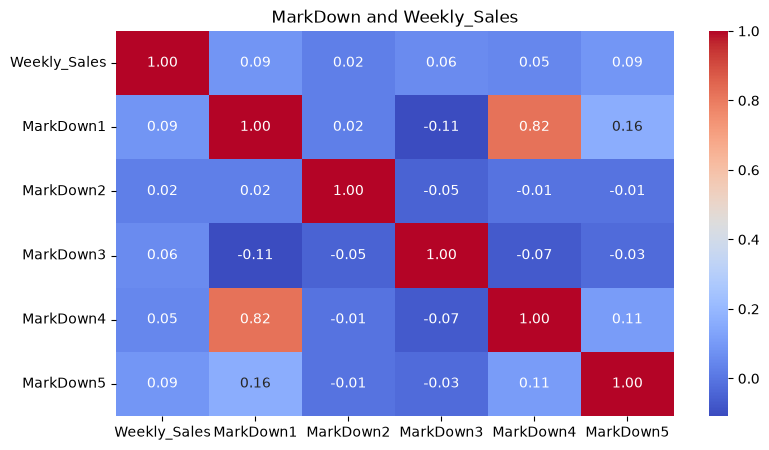

In [40]:
import seaborn as sns

plt.figure(figsize=(9,5))
sns.heatmap(markdown_relation,annot=True,cmap='coolwarm',fmt='.2f')

plt.title('MarkDown and Weekly_Sales')
plt.show()

Store
20   301397792.46
4    299543953.38
14   288999911.34
13   286517703.80
2    275382440.98
10   271617713.89
27   253855916.88
6    223756130.64
1    222402808.85
39   207445542.47
Name: Weekly_Sales, dtype: float64


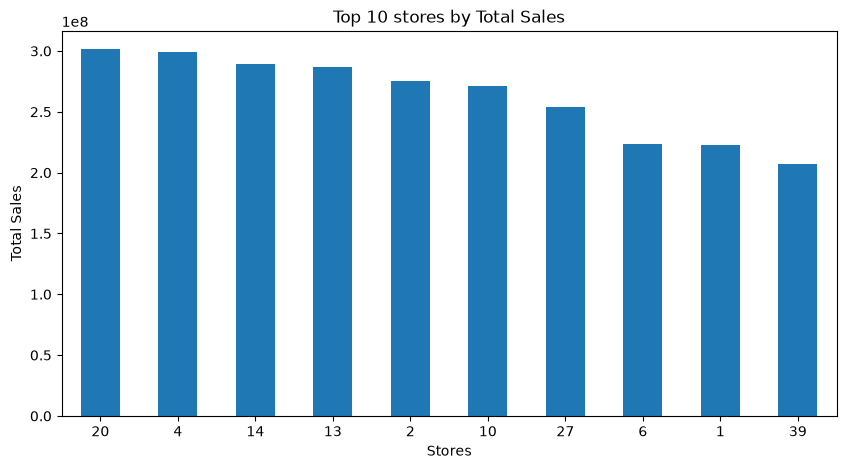

In [41]:
stores_sales = train.groupby('Store')['Weekly_Sales'].sum()

top_stores = stores_sales.sort_values(ascending=False).head(10)

print(top_stores)            # identify top 10 stores generating the highest total sales

top_stores.plot(kind='bar', figsize=(10,5))

plt.title('Top 10 stores by Total Sales')
plt.xlabel('Stores')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)

plt.show()

In [42]:

# Monthly and yeearly trends

In [43]:
train['Date'] = pd.to_datetime(train['Date'])

train['Date'].dtype            # Correct DateTime format 

dtype('<M8[us]')

In [44]:
train['Year'] = train['Date'].dt.year
train['Month'] = train['Date'].dt.month

train[['Date', 'Year','Month']].head(10)

,Date,Year,Month
0,2010-02-05,2010,2
1,2010-02-12,2010,2
2,2010-02-19,2010,2
3,2010-02-26,2010,2
4,2010-03-05,2010,3
5,2010-03-12,2010,3
6,2010-03-19,2010,3
7,2010-03-26,2010,3
8,2010-04-02,2010,4
9,2010-04-09,2010,4


In [45]:
monthly_sales = train.groupby('Month')['Weekly_Sales'].sum()

monthly_sales

Month
1    332598438.49
2    568727890.45
3    592785901.28
4    646859784.97
5    557125571.95
6    622629886.84
7    650000977.25
8    613090208.82
9    578761179.26
10   584784787.59
11   413015725.01
12   576838635.20
Name: Weekly_Sales, dtype: float64

In [46]:
# Business insight : July has generated the highest combined sales across the observed years.

In [47]:
yearly_sales = train.groupby('Year')['Weekly_Sales'].sum()

yearly_sales     

Year
2010   2288886120.41
2011   2448200007.35
2012   2000132859.35
Name: Weekly_Sales, dtype: float64

In [48]:
# Business insight: 2011 recorded the highest total sales, approximately $2.45 billion

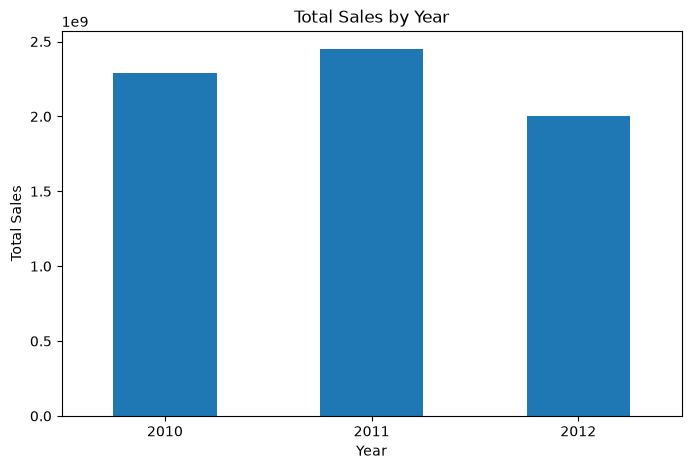

In [49]:
yearly_sales.plot(kind='bar', figsize=(8,5))

plt.title('Total Sales by Year')
plt.xlabel('Year')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.show()


In [50]:
#fair sales comparision : 2011 vs 2012

In [51]:
comparison = train[
    (train['Year'].isin([2011,2012])) &
    (train['Month'] <= 10)
].groupby('Year')['Weekly_Sales'].sum()


comparison

Year
2011   1949959550.00
2012   2000132859.35
Name: Weekly_Sales, dtype: float64

2012 has the highest sale: january through october


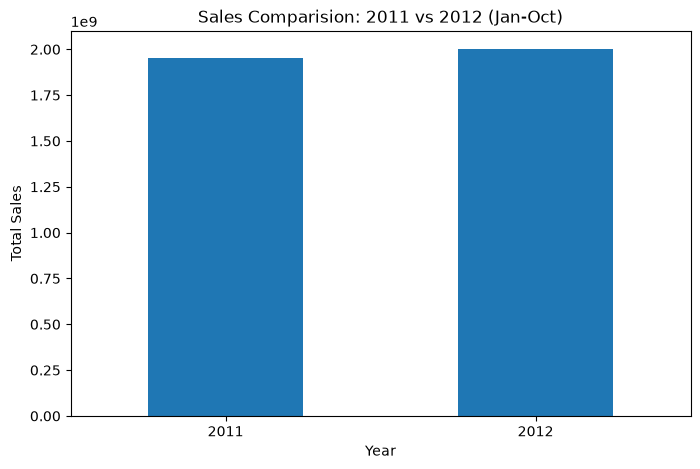

In [52]:
comparison.plot(kind='bar', figsize=(8,5))

plt.title('Sales Comparision: 2011 vs 2012 (Jan-Oct)')
plt.xlabel('Year')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)

plt.show()

In [53]:
year_month_sales = train.groupby(['Year', 'Month'])['Weekly_Sales'].sum()

year_month_sales

Year  Month
2010  2       190332983.04
      3       181919802.50
      4       231412368.05
      5       186710934.34
      6       192246172.36
      7       232580125.98
      8       187640110.89
      9       177267896.37
      10      217161824.02
      11      202853370.14
      12      288760532.72
2011  1       163703966.83
      2       186331327.87
      3       179356448.29
      4       226526510.97
      5       181648158.16
      6       189773385.19
      7       229911398.87
      8       188599332.25
      9       220847738.42
      10      183261283.15
      11      210162354.87
      12      288078102.48
2012  1       168894471.66
      2       192063579.54
      3       231509650.49
      4       188920905.95
      5       188766479.45
      6       240610329.29
      7       187509452.40
      8       236850765.68
      9       180645544.47
      10      184361680.42
Name: Weekly_Sales, dtype: float64

In [54]:
train.groupby('Year')['Month'].unique()   # checking available months

Year
2010       [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
2011    [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
2012            [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Name: Month, dtype: object

In [55]:
year_month_sales = year_month_sales.unstack(level=0)  

year_month_sales  # Restructuring our data

Year,2010,2011,2012
Month,,,
1,NaN,163703966.83,168894471.66
2,190332983.04,186331327.87,192063579.54
3,181919802.50,179356448.29,231509650.49
4,231412368.05,226526510.97,188920905.95
5,186710934.34,181648158.16,188766479.45
6,192246172.36,189773385.19,240610329.29
7,232580125.98,229911398.87,187509452.40
8,187640110.89,188599332.25,236850765.68
9,177267896.37,220847738.42,180645544.47


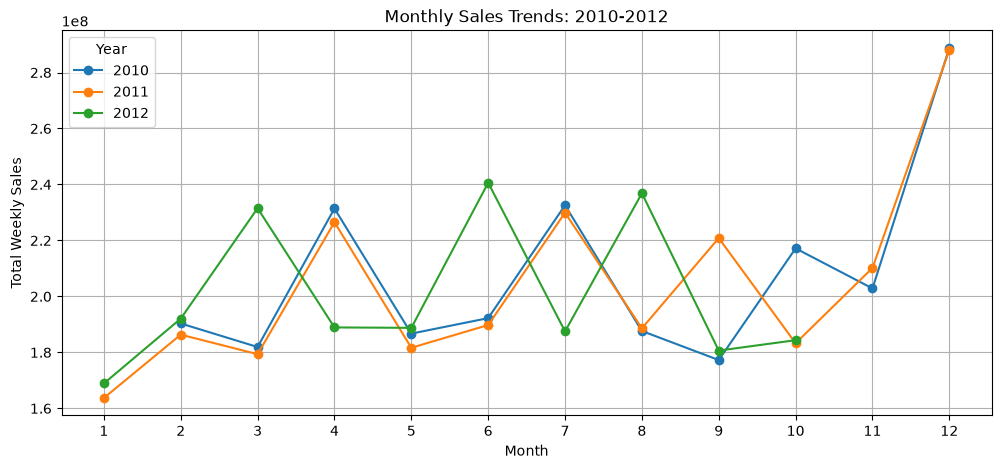

In [56]:
year_month_sales.plot(kind='line', marker='o',figsize=(12,5))

plt.title('Monthly Sales Trends: 2010-2012')
plt.xlabel('Month')
plt.ylabel('Total Weekly Sales')
plt.xticks(range(1,13))
plt.legend(title='Year')
plt.grid()
plt.show()

In [57]:
monthly_week_counts = train.groupby(['Year', 'Month'])['Date'].nunique().unstack(level=0)

monthly_week_counts

Year,2010,2011,2012
Month,,,
1,NaN,4.00,4.00
2,4.00,4.00,4.00
3,4.00,4.00,5.00
4,5.00,5.00,4.00
5,4.00,4.00,4.00
6,4.00,4.00,5.00
7,5.00,5.00,4.00
8,4.00,4.00,5.00
9,4.00,5.00,4.00


In [58]:
average_weekly_sales = (year_month_sales / monthly_week_counts ) 

average_weekly_sales          # Average sales per week

Year,2010,2011,2012
Month,,,
1,NaN,40925991.71,42223617.91
2,47583245.76,46582831.97,48015894.88
3,45479950.62,44839112.07,46301930.10
4,46282473.61,45305302.19,47230226.49
5,46677733.59,45412039.54,47191619.86
6,48061543.09,47443346.30,48122065.86
7,46516025.20,45982279.77,46877363.10
8,46910027.72,47149833.06,47370153.14
9,44316974.09,44169547.68,45161386.12


In [59]:
average_weekly_sales.idxmax()

Year
2010    12
2011    12
2012     6
dtype: int32

Business insight: December recorded highest average weekly sales in 2010 and 2011, 
                  suggesting higher customer demand during holiday

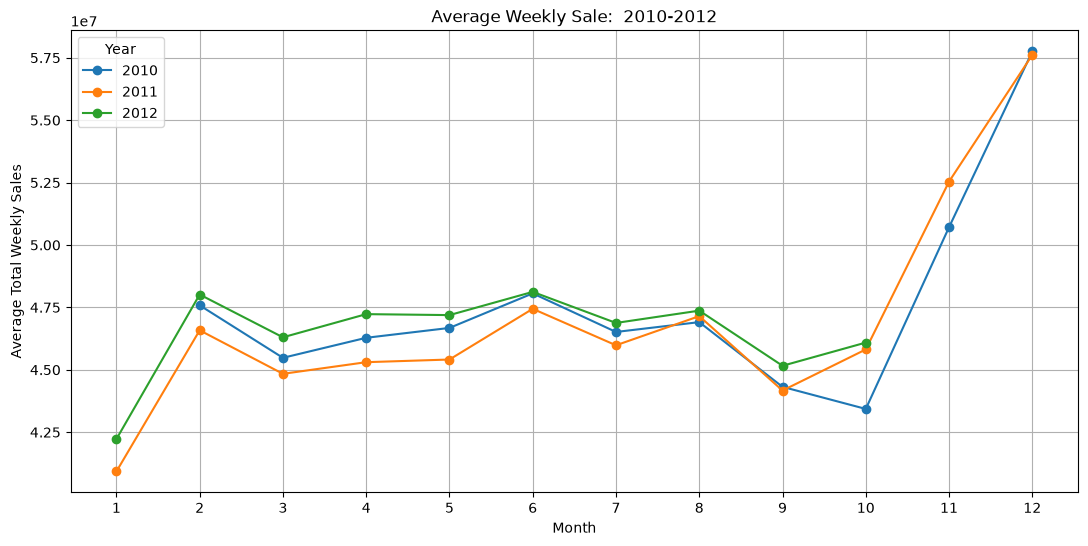

In [60]:
average_weekly_sales.plot(kind='line',marker='o',figsize=(13,6))

plt.title('Average Weekly Sale:  2010-2012')
plt.xlabel('Month')
plt.ylabel('Average Total Weekly Sales')
plt.xticks(range(1,13))
plt.legend(title='Year')
plt.grid()
plt.show()


In [61]:
# Seasonal Analysis

In [62]:
train['Quarter'] = train['Date'].dt.quarter

train[['Date','Year','Month','Quarter']].head(10)        

,Date,Year,Month,Quarter
0,2010-02-05,2010,2,1
1,2010-02-12,2010,2,1
2,2010-02-19,2010,2,1
3,2010-02-26,2010,2,1
4,2010-03-05,2010,3,1
5,2010-03-12,2010,3,1
6,2010-03-19,2010,3,1
7,2010-03-26,2010,3,1
8,2010-04-02,2010,4,2
9,2010-04-09,2010,4,2


grouping sales by year and quarter to find out how much walmart generated in each quarter

In [63]:
quarterly_sales = train.groupby(['Year', 'Quarter',])['Weekly_Sales'].sum().unstack(level=0)

quarterly_sales

Year,2010,2011,2012
Quarter,,,
1,372252785.54,529391742.99,592467701.69
2,610369474.75,597948054.32,618297714.69
3,597488133.24,639358469.54,605005762.55
4,708775726.88,681501740.50,184361680.42


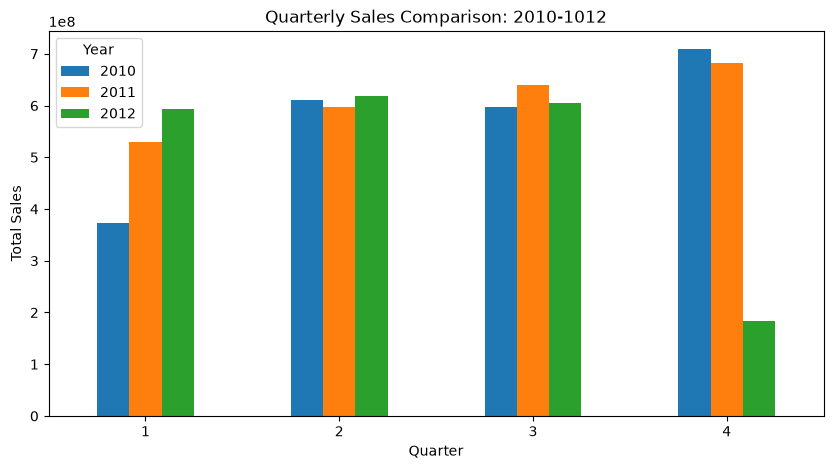

In [64]:
quarterly_sales.plot(kind='bar', figsize=(10,5))

plt.title('Quarterly Sales Comparison: 2010-1012')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.show()


Business insight: Q4 generated the highest sales in 2010 and 2011, while Q2 led in 2012 

In [65]:
quarterly_sales.idxmax()

Year
2010    4
2011    4
2012    2
dtype: int32

In [66]:
# Store performance comparision

In [67]:
store_avg_sales = train.groupby('Store')['Weekly_Sales'].mean().sort_values(ascending=False)

store_avg_sales.head(10)       # avg weekly sales

Store
20   29508.30
4    29161.21
14   28784.85
13   27355.14
2    26898.07
10   26332.30
27   24826.98
6    21913.24
1    21710.54
39   21000.76
Name: Weekly_Sales, dtype: float64

Buiness insight: Store 20 leads in avgerage weekly sales, followed by Store 4 and 14 

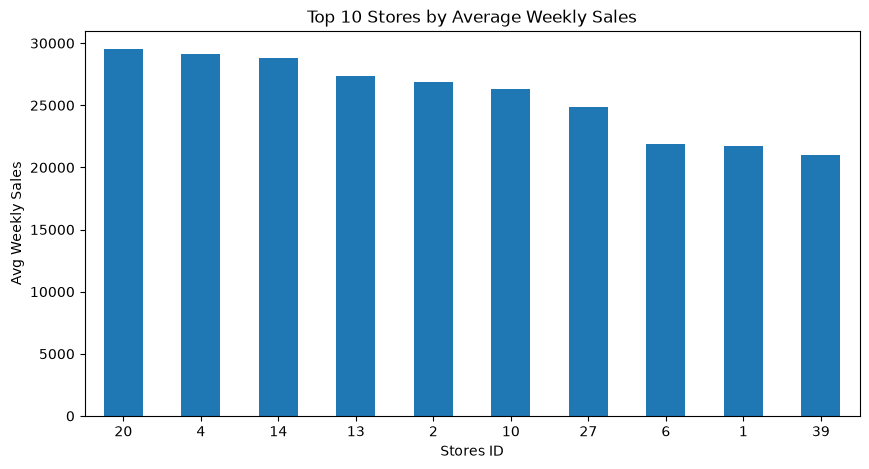

In [68]:
store_avg_sales.head(10).plot(kind='bar', figsize=(10,5))


plt.title('Top 10 Stores by Average Weekly Sales')
plt.xlabel('Stores ID')
plt.ylabel('Avg Weekly Sales')
plt.xticks(rotation=0)
plt.show()

In [69]:
dept_avg_sales = train.groupby('Dept')['Weekly_Sales'].mean().sort_values(ascending=False)

dept_avg_sales.head(10)

Dept
92   75204.87
95   69824.42
38   61090.62
72   50566.52
65   45441.71
90   45232.08
40   44900.70
2    43607.02
91   33687.91
94   33405.88
Name: Weekly_Sales, dtype: float64

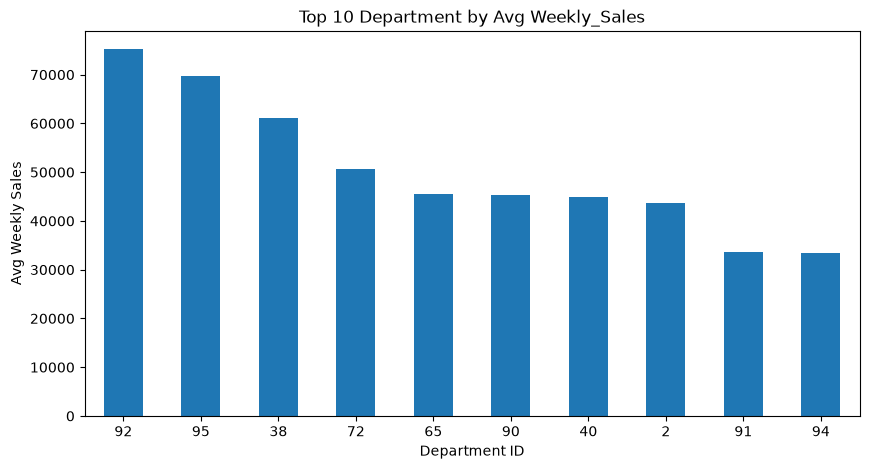

In [70]:
dept_avg_sales.head(10).plot(kind='bar', figsize=(10,5))


plt.title('Top 10 Department by Avg Weekly_Sales')
plt.xlabel('Department ID')
plt.ylabel('Avg Weekly Sales')
plt.xticks(rotation=0)
plt.show()


Business insight:  Department 92 records highest weekly sales followed by Department 95 and 38

In [71]:
# Final analysis

Combined Weekly sales across all recored stores, departments and dates

In [72]:
total_sales = train['Weekly_Sales'].sum()

total_sales

np.float64(6737218987.110001)

Average per store-department-week record

In [73]:
average_sales = train['Weekly_Sales'].mean()

average_sales

np.float64(15981.258123467042)

Counting Total Records

In [74]:
total_records = train.shape[0]

total_records

421570

Summary 

In [76]:
print('WALMART SALES SUMMARY')
print('-------------------------------------')

print(f'Total_Records: {total_records:,}')
print(f'Total_Sales: ${total_sales:,.2f}')
print(f'Average Weekly Sales: ${average_sales:,.2f}')

WALMART SALES SUMMARY
-------------------------------------
Total_Records: 421,570
Total_Sales: $6,737,218,987.11
Average Weekly Sales: $15,981.26
